# Extracción documental bancaria
Ejecuta las celdas en orden. El notebook muestra las siete etapas sobre un informe y usa el mismo código para el lote de `datos/Banco`.

## 1. Ingesta documental
El índice localiza el PDF original. Se registra su ruta relativa, SHA-256, tamaño, metadatos del PDF y metadatos del índice.

In [1]:
from pathlib import Path

import pandas as pd
import pymupdf
from IPython.display import FileLink, Image, display

import extraccion_bancaria as flujo

raiz = Path.cwd()
corpus = raiz / "datos" / "Banco"
destino = raiz / "salidas" / "arquitectura_bancaria"
print(flujo.configurar_entorno())
inventario, incidencias = flujo.cargar_inventario(corpus)
if not inventario:
    raise ValueError("El índice no contiene PDF disponibles.")
ejemplo = inventario[0]
documento = flujo.ingestar(ejemplo)
print(f"{len(inventario)} PDF disponibles · {len(incidencias)} incidencias del índice")
display(pd.Series({k: v for k, v in documento.items() if k not in {"indice", "pdf"}}))

{'java': 'C:\\Program Files\\Eclipse Adoptium\\jre-17.0.21.10002-hotspot\\bin\\java.EXE', 'tesseract': '5.4.0.20240606'}
48 PDF disponibles · 0 incidencias del índice


archivo        AGROBANCO/APOYO Y ASOCIADOS INTERNACIONALES/B+...
sha256         6a845c8a975a41206eefb1bd9a9c9f9f4cd27dd0ab9f48...
bytes                                                    1171069
num_paginas                                                    9
dtype: object

## 2. Análisis por página
Se mide la capa de texto y se inventarían las imágenes y grupos vectoriales. La clasificación de página usa el volumen de texto y la superficie de las imágenes. Puedes cambiar la página para comparar perfiles.

In [2]:
numero_pagina = 1

with pymupdf.open(ejemplo["ruta"]) as pdf:
    perfiles = [flujo.analizar_pagina(p) for p in pdf]
perfil = perfiles[numero_pagina - 1]
display(pd.DataFrame([
    {"página": p["pagina"], "tipo": p["tipo"], "caracteres": p["caracteres_nativos"],
     "imágenes": len(p["imagenes"]), "grupos vectoriales": len(p["vectores"])}
    for p in perfiles
]))

,página,tipo,caracteres,imágenes,grupos vectoriales
0,1,digital,4689,2,0
1,2,digital,4957,2,1
2,3,digital,3887,4,1
3,4,digital,3731,5,0
4,5,digital,4016,4,0
5,6,digital,3783,5,0
6,7,digital,3021,2,0
7,8,digital,6131,2,1
8,9,digital,4970,2,1


## 3. Layout y orden de lectura
PyMuPDF extrae el texto y localiza candidatos de tabla. Tabula-py extrae sus celdas. Tesseract lee gráficos candidatos y páginas sin capa útil de texto. La vista marca el orden estimado. Las tablas rasterizadas se señalan para revisión.

Consider using the pymupdf_layout package for a greatly improved page layout analysis.


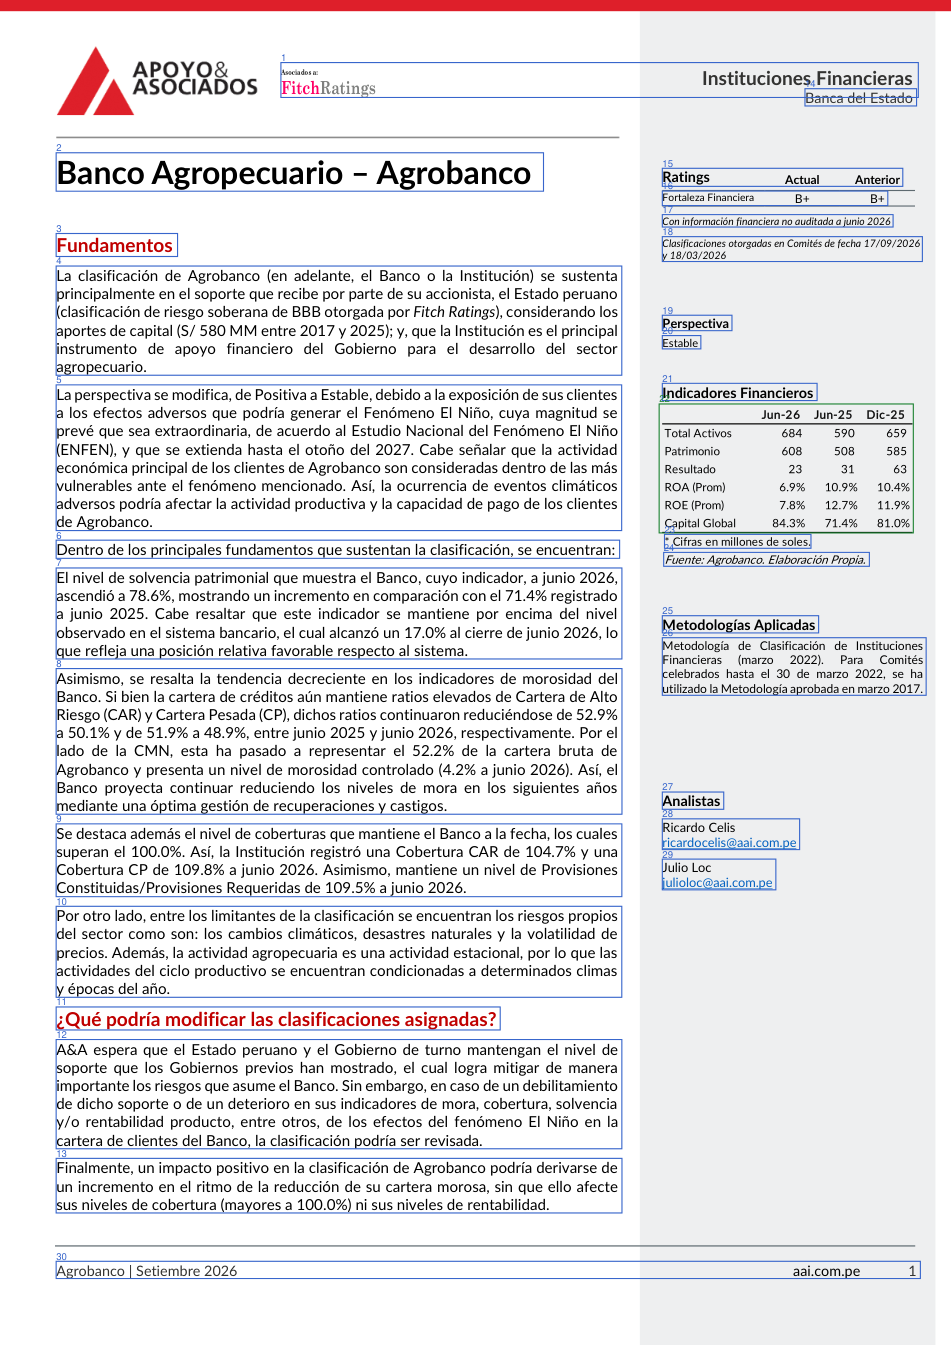

,orden,tipo,motor,caja,confianza
0,1,texto,pymupdf,"[175.91, 39.18, 574.97, 61.04]",NaN
1,2,titulo,pymupdf,"[35.16, 95.68, 340.31, 119.73]",NaN
2,3,titulo,pymupdf,"[35.16, 146.22, 111.18, 160.62]",NaN
3,4,texto,pymupdf,"[35.16, 166.58, 389.33, 234.96]",NaN
4,5,texto,pymupdf,"[35.16, 240.98, 389.23, 332.19]",NaN
5,6,texto,pymupdf,"[35.16, 338.21, 387.97, 349.59]",NaN
6,7,texto,pymupdf,"[35.16, 355.61, 389.38, 412.59]",NaN
7,8,texto,pymupdf,"[35.16, 418.61, 389.41, 509.81]",NaN
8,9,texto,pymupdf,"[35.16, 515.83, 389.37, 561.41]",NaN
9,10,texto,pymupdf,"[35.16, 567.43, 389.33, 624.41]",NaN


In [3]:
colores = {"tabla": (0.12, 0.52, 0.2), "grafico": (0.8, 0.35, 0.16), "ocr_pagina": (0.8, 0.35, 0.16)}
with pymupdf.open(ejemplo["ruta"]) as pdf:
    pagina = pdf[numero_pagina - 1]
    regiones, avisos = flujo.extraer_layout(ejemplo["ruta"], pagina, perfil)
    for r in regiones:
        rect = pymupdf.Rect(r["caja"])
        color = colores.get(r["tipo"], (0.22, 0.4, 0.8))
        pagina.draw_rect(rect, color=color, width=0.7)
        pagina.insert_text((rect.x0, max(7, rect.y0 - 1)), str(r["orden"]), color=color, fontsize=6)
    display(Image(data=pagina.get_pixmap(dpi=115).tobytes("png")))

display(pd.DataFrame(regiones, columns=["orden", "tipo", "motor", "caja", "confianza"]))
if avisos:
    display(pd.DataFrame(avisos))

## 4. Limpieza y reconstrucción
Se normalizan párrafos y títulos, se eliminan saltos de línea de maquetación, se completan las dimensiones de las tablas y se conservan las unidades explícitas.

In [4]:
reconstruidas = flujo.reconstruir(regiones)
display(pd.DataFrame([
    {"orden": r["orden"], "tipo": r["tipo"], "texto": r["texto"][:160], "unidades": r["unidades"]}
    for r in reconstruidas
]).head(16))
for tabla in (r for r in reconstruidas if r["tipo"] == "tabla"):
    display(pd.DataFrame(tabla["filas"]))

,orden,tipo,texto,unidades
0,1,texto,Asociados a: FitchRatings Instituciones Financ...,[]
1,2,titulo,Banco Agropecuario – Agrobanco,[]
2,3,titulo,Fundamentos,[]
3,4,texto,"La clasificación de Agrobanco (en adelante, el...",[S/]
4,5,texto,"La perspectiva se modifica, de Positiva a Esta...",[]
5,6,texto,Dentro de los principales fundamentos que sust...,[]
6,7,texto,El nivel de solvencia patrimonial que muestra ...,[%]
7,8,texto,"Asimismo, se resalta la tendencia decreciente ...",[%]
8,9,texto,Se destaca además el nivel de coberturas que m...,"[%, s/]"
9,10,texto,"Por otro lado, entre los limitantes de la clas...",[]


,0,1,2,3
0,,Jun-26,Jun-25,Dic-25
1,Total Activos,684,590,659
2,Patrimonio,608,508,585
3,Resultado,23,31,63
4,ROA (Prom),6.9%,10.9%,10.4%
5,ROE (Prom),7.8%,12.7%,11.9%
6,Capital Global,84.3%,71.4%,81.0%


## 5. Extracción semántica
Las entidades del catálogo conservan el origen `indice`. Las menciones detectadas en el PDF llevan evidencia por página. Las reglas extraen calificaciones rotuladas, perspectivas, fechas e indicadores tabulares con evidencia. Los valores sin unidad o período explícitos quedan sin completar.

In [5]:
pagina_procesada = {**perfil, "regiones": reconstruidas, "avisos": avisos}
campos = flujo.extraer_semantica(documento, [pagina_procesada])
display(pd.DataFrame(campos))

,tipo,valor,origen,evidencia,pagina,orden,caja,normalizado,nombre,periodo,unidad,evidencia_unidad
0,entidad,AGROBANCO,indice,AGROBANCO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,clasificadora,APOYO Y ASOCIADOS INTERNACIONALES,indice,APOYO Y ASOCIADOS INTERNACIONALES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,entidad,Agrobanco,pymupdf,Agrobanco,1.0,2.0,"[35.16, 95.68, 340.31, 119.73]",NaN,NaN,NaN,NaN,NaN
3,entidad,Agrobanco,pymupdf,Agrobanco,1.0,4.0,"[35.16, 166.58, 389.33, 234.96]",NaN,NaN,NaN,NaN,NaN
4,entidad,Agrobanco,pymupdf,Agrobanco,1.0,5.0,"[35.16, 240.98, 389.23, 332.19]",NaN,NaN,NaN,NaN,NaN
5,entidad,Agrobanco,pymupdf,Agrobanco,1.0,8.0,"[35.16, 418.61, 389.41, 509.81]",NaN,NaN,NaN,NaN,NaN
6,entidad,Agrobanco,pymupdf,Agrobanco,1.0,13.0,"[35.16, 725.26, 389.41, 759.44]",NaN,NaN,NaN,NaN,NaN
7,calificacion_pdf,B+,pymupdf,Fortaleza Financiera B+,1.0,16.0,"[414.7, 119.62, 555.86, 128.71]",NaN,NaN,NaN,NaN,NaN
8,fecha,17/09/2026,pymupdf,17/09/2026,1.0,18.0,"[414.7, 148.18, 577.52, 163.76]",2026-09-17,NaN,NaN,NaN,NaN
9,fecha,18/03/2026,pymupdf,18/03/2026,1.0,18.0,"[414.7, 148.18, 577.52, 163.76]",2026-03-18,NaN,NaN,NaN,NaN


## 6. Control de calidad
Se registran alertas de cobertura, errores de lectura, fechas inválidas, indicadores sin período y discrepancias de calificación. Un documento puede requerir revisión aunque sus restantes páginas y evidencias se exporten.

In [6]:
alertas = flujo.controlar_calidad(documento, [pagina_procesada], campos)
display(pd.DataFrame(alertas, columns=["pagina", "regla", "detalle"]))

,pagina,regla,detalle


## 7. Procesar el lote y almacenar
Por defecto se ejecuta un PDF por clasificadora. Cambia `lote_completo` a `True` para procesar todo el índice. Cada corrida publica Parquet de documentos, páginas, regiones, campos y alertas, junto con un reporte HTML. Las regiones se enlazan por archivo, página y orden.

In [7]:
lote_completo = True

muestra = {}
for entrada in inventario:
    muestra.setdefault(entrada["indice"]["clasificadora"], entrada)
seleccion = inventario if lote_completo else list(muestra.values())

resultados = []
for numero, entrada in enumerate(seleccion, 1):
    resultado = flujo.procesar(entrada)
    resultados.append(resultado)
    print(f"{numero}/{len(seleccion)} · {resultado['documento']['estado']} · {entrada['archivo']}", flush=True)

corrida = flujo.exportar(resultados, incidencias, destino)
display(pd.read_parquet(corrida / "documentos.parquet")[["archivo", "tipo_pdf", "num_paginas", "estado"]])
display(FileLink(str((corrida / "reporte.html").relative_to(raiz))))

1/48 · ok · AGROBANCO/APOYO Y ASOCIADOS INTERNACIONALES/B+_e5c84757b53e.pdf
2/48 · ok · ALFIN BANCO/JCR LATINO AMERICA/A-_a88eaa4adf96.pdf
3/48 · revisar · ALFIN BANCO/PCR (PACIFIC CREDIT RATING)/B+_bb5600d68af9.pdf
4/48 · revisar · BANBIF/MOODYS LOCAL PE CLASIFICADORA DE RIESGO/A_07e741879141.pdf
5/48 · revisar · BANBIF/PCR (PACIFIC CREDIT RATING)/A+_3d4c843f48ba.pdf
6/48 · ok · BANCO BCI/APOYO Y ASOCIADOS INTERNACIONALES/A_85216f0ff534.pdf
7/48 · revisar · BANCO BCI/MOODYS LOCAL PE CLASIFICADORA DE RIESGO/A_e1af4894f310.pdf
8/48 · ok · BANCO DE CREDITO/APOYO Y ASOCIADOS INTERNACIONALES/A+_589d1852a7b2.pdf
9/48 · revisar · BANCO DE CREDITO/MOODYS LOCAL PE CLASIFICADORA DE RIESGO/A+_07a04c86538c.pdf
10/48 · revisar · BANCO DE CREDITO/PCR (PACIFIC CREDIT RATING)/A+_0c5bada0de27.pdf
11/48 · revisar · BANCO EFECTIVA/JCR LATINO AMERICA/A_f107a23a9005.pdf
12/48 · revisar · BANCO EFECTIVA/MOODYS LOCAL PE CLASIFICADORA DE RIESGO/A-_0b10d1668b88.pdf
13/48 · revisar · BANCO EFECTIVA/PCR (PACIFI

,archivo,tipo_pdf,num_paginas,estado
0,AGROBANCO/APOYO Y ASOCIADOS INTERNACIONALES/B+...,digital,9,ok
1,ALFIN BANCO/JCR LATINO AMERICA/A-_a88eaa4adf96...,mixto,27,ok
2,ALFIN BANCO/PCR (PACIFIC CREDIT RATING)/B+_bb5...,digital,13,revisar
3,BANBIF/MOODYS LOCAL PE CLASIFICADORA DE RIESGO...,digital,10,revisar
4,BANBIF/PCR (PACIFIC CREDIT RATING)/A+_3d4c843f...,digital,12,revisar
5,BANCO BCI/APOYO Y ASOCIADOS INTERNACIONALES/A_...,digital,9,ok
6,BANCO BCI/MOODYS LOCAL PE CLASIFICADORA DE RIE...,digital,9,revisar
7,BANCO DE CREDITO/APOYO Y ASOCIADOS INTERNACION...,digital,10,ok
8,BANCO DE CREDITO/MOODYS LOCAL PE CLASIFICADORA...,digital,9,revisar
9,BANCO DE CREDITO/PCR (PACIFIC CREDIT RATING)/A...,digital,11,revisar


C:\Proyectos\project-final-sbs-e5\salidas\arquitectura_bancaria\20261125T155501Z-670951fb\reporte.html